# Mini-Project #2: Simple Linear Regression (OLS)
## Measuring Correlation between Student GPA and the AI-to-Study Hours Ratio: STEM vs. Non-STEM Cohorts
**Data Science Course (ISEN5)**  
**Instructor:** Iyad Zaarour  
**Method:** Ordinary Least Squares (OLS) Linear Regression  

---

### Project Objectives & Core Concepts:
1. **Feature Engineering:** Calculate the **AI-to-Study Hours Ratio**:
   $$\text{AI\_to\_Study\_Ratio} = \frac{\text{Weekly\_GenAI\_Hours}}{\text{Traditional\_Study\_Hours}}$$
   This metric gauges student reliance on AI relative to foundational manual studying.
2. **Cohort Segmentation:** Compare **STEM** vs. **Non-STEM** students.
3. **Train/Test Splitting:** Split each cohort into **70% Training** and **30% Testing** subsets (`test_size=0.30`).
4. **OLS Model Training:** Fit simple linear regression models ($Y = mX + b$) using `sklearn.linear_model.LinearRegression` to predict **GPA** ($Y$) from the **AI-to-Study Hours Ratio** ($X$).
5. **Model Evaluation:** Compute error metrics on both Training and Testing sets:
   - **SSE** (Sum of Squared Errors)
   - **MSE** (Mean Squared Error)
   - **RMSE** (Root Mean Squared Error)
   - **MAE** (Mean Absolute Error)
   - **$R^2$** (Coefficient of Determination)
6. **Model Assessment & Overfitting Analysis:** Compare train and test errors to evaluate generalization and test for overfitting/underfitting.


In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import kagglehub

# Display plots inline
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


## 1. Data Collection & Loading
We load the dataset `ai-impact-on-students` (50,000 student records).  
The loader automatically checks local directories first, and falls back to `kagglehub` if running on a fresh environment like Google Colab.


In [2]:
# Check local path first, otherwise download via kagglehub
dataset_filename = "ai_student_impact_dataset.csv"
local_candidates = [
    dataset_filename,
    os.path.join("Class 2", dataset_filename),
    "ai_student_impact_dataset (1).csv",
    os.path.join("Class 2", "ai_student_impact_dataset (1).csv")
]

file_path = None
for candidate in local_candidates:
    if os.path.exists(candidate):
        file_path = candidate
        break

if file_path is None:
    print("Downloading dataset via kagglehub...")
    download_dir = kagglehub.dataset_download("laveshjadon/ai-impact-on-students")
    file_path = os.path.join(download_dir, "ai_student_impact_dataset (1).csv")

df = pd.read_csv(file_path)
print(f"Loaded dataset from: {file_path}")
print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()


Loaded dataset from: Class 2/ai_student_impact_dataset.csv
Dataset Shape: 50,000 rows, 16 columns


## 2. Feature Engineering & Cohort Segmentation
We engineer the key independent variable:
$$\text{AI\_to\_Study\_Ratio} = \frac{\text{Weekly\_GenAI\_Hours}}{\text{Traditional\_Study\_Hours}}$$

- A ratio **$< 1$** indicates that the student spends more time in traditional study than using AI.
- A ratio **$> 1$** indicates that AI usage exceeds traditional study time.

We segment the students into two groups based on `Major_Category`:
- **STEM Cohort**: Science, Technology, Engineering, and Mathematics (`Major_Category == 'STEM'`).
- **Non-STEM Cohort**: Humanities, Business, Medical, and Arts (`Major_Category != 'STEM'`).


In [3]:
# Compute the AI-to-Study Hours Ratio
df['AI_to_Study_Ratio'] = df['Weekly_GenAI_Hours'] / df['Traditional_Study_Hours']

print("Summary Statistics of the Ratio and Study Metrics:")
print(df[['Weekly_GenAI_Hours', 'Traditional_Study_Hours', 'AI_to_Study_Ratio', 'Post_Semester_GPA']].describe())

# Segment cohorts
df_stem = df[df['Major_Category'] == 'STEM'].copy()
df_non_stem = df[df['Major_Category'] != 'STEM'].copy()

print(f"\nTotal STEM Students:     {len(df_stem):,} ({len(df_stem)/len(df)*100:.1f}%)")
print(f"Total Non-STEM Students: {len(df_non_stem):,} ({len(df_non_stem)/len(df)*100:.1f}%)")

# Pearson correlation coefficients
corr_stem = df_stem['AI_to_Study_Ratio'].corr(df_stem['Post_Semester_GPA'])
corr_non_stem = df_non_stem['AI_to_Study_Ratio'].corr(df_non_stem['Post_Semester_GPA'])

print(f"\nPearson Correlation (AI-to-Study Ratio vs. GPA):")
print(f"  STEM:     r = {corr_stem:.4f}")
print(f"  Non-STEM: r = {corr_non_stem:.4f}")


Summary Statistics of the Ratio and Study Metrics:
       Weekly_GenAI_Hours  ...  Post_Semester_GPA
count        50000.000000  ...       50000.000000
mean             8.427752  ...           3.349299
std              8.269490  ...           0.495673
min              0.000000  ...           1.000000
25%              2.390000  ...           3.023750
50%              5.800000  ...           3.421000
75%             11.720000  ...           3.749000
max             40.000000  ...           4.000000

[8 rows x 4 columns]

Total STEM Students:     15,059 (30.1%)
Total Non-STEM Students: 34,941 (69.9%)

Pearson Correlation (AI-to-Study Ratio vs. GPA):
  STEM:     r = -0.0750
  Non-STEM: r = -0.0496


## 3. Data Splitting: 70% Training and 30% Testing
Following the project specifications:
- **70% Training Set:** Used to train the OLS linear regression model parameters ($m$ and $b$).
- **30% Testing Set:** Kept unseen during training; used to assess generalization and test for overfitting.

We set `random_state=42` to ensure consistent and reproducible results.


In [4]:
# Define feature X and target y for both cohorts
X_stem = df_stem[['AI_to_Study_Ratio']]
y_stem = df_stem['Post_Semester_GPA']

X_non_stem = df_non_stem[['AI_to_Study_Ratio']]
y_non_stem = df_non_stem['Post_Semester_GPA']

# 70% Training / 30% Testing split
X_train_stem, X_test_stem, y_train_stem, y_test_stem = train_test_split(
    X_stem, y_stem, test_size=0.30, random_state=42
)

X_train_non, X_test_non, y_train_non, y_test_non = train_test_split(
    X_non_stem, y_non_stem, test_size=0.30, random_state=42
)

print(f"STEM     -> Train set: {X_train_stem.shape[0]:,} samples | Test set: {X_test_stem.shape[0]:,} samples")
print(f"Non-STEM -> Train set: {X_train_non.shape[0]:,} samples | Test set: {X_test_non.shape[0]:,} samples")


STEM     -> Train set: 10,541 samples | Test set: 4,518 samples
Non-STEM -> Train set: 24,458 samples | Test set: 10,483 samples


## 4. Evaluation Criteria
As defined in the project instructions and starter code, we compute:
1. **SSE (Sum of Squared Errors / Residual Sum of Squares):**
   $$\text{SSE} = \sum_{i=1}^n (y_i - \hat{y}_i)^2$$
2. **MSE (Mean Squared Error):**
   $$\text{MSE} = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2$$
3. **RMSE (Root Mean Squared Error):**
   $$\text{RMSE} = \sqrt{\text{MSE}}$$
4. **MAE (Mean Absolute Error):**
   $$\text{MAE} = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i|$$
5. **$R^2$ (Coefficient of Determination):**
   $$R^2 = 1 - \frac{\text{SSE}}{\text{SST}}$$


In [5]:
def compute_metrics(y_true, y_pred, name=""):
    sse = np.sum((y_true - y_pred) ** 2)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    print(f"{name} Metrics:")
    print(f"  SSE  (Sum of Squared Errors):       {sse:12.4f}")
    print(f"  MSE  (Mean Squared Error):          {mse:12.6f}")
    print(f"  RMSE (Root Mean Squared Error):     {rmse:12.6f}")
    print(f"  MAE  (Mean Absolute Error):         {mae:12.6f}")
    print(f"  R²   (Coefficient of Determination):{r2:12.6f}")
    
    return {"SSE": sse, "MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2}


## 5. Model 1: STEM Students Linear Regression (OLS)
We train the Ordinary Least Squares (OLS) model on the STEM training dataset and evaluate its performance on both the training and test sets.


In [6]:
# Fit OLS Linear Regression for STEM
reg_stem = LinearRegression()
reg_stem.fit(X_train_stem, y_train_stem)

slope_stem = reg_stem.coef_[0]
intercept_stem = reg_stem.intercept_

print("STEM Model Fitted Equation:")
print(f"  GPA = ({slope_stem:.6f}) * AI_to_Study_Ratio + ({intercept_stem:.6f})")
print(f"  Slope (m):     {slope_stem:.6f}")
print(f"  Intercept (b): {intercept_stem:.6f}")


STEM Model Fitted Equation:
  GPA = (-0.009201) * AI_to_Study_Ratio + (3.376136)
  Slope (m):     -0.009201
  Intercept (b): 3.376136


In [7]:
# Model predictions for STEM
y_pred_train_stem = reg_stem.predict(X_train_stem)
y_pred_test_stem = reg_stem.predict(X_test_stem)

print("=" * 60)
metrics_train_stem = compute_metrics(y_train_stem, y_pred_train_stem, "STEM Training Set (70%)")
print("-" * 60)
metrics_test_stem = compute_metrics(y_test_stem, y_pred_test_stem, "STEM Testing Set (30%)")
print("=" * 60)


STEM Training Set (70%) Metrics:
  SSE  (Sum of Squared Errors):          2587.8187
  MSE  (Mean Squared Error):              0.245500
  RMSE (Root Mean Squared Error):         0.495480
  MAE  (Mean Absolute Error):             0.407465
  R²   (Coefficient of Determination):    0.005312
------------------------------------------------------------
STEM Testing Set (30%) Metrics:
  SSE  (Sum of Squared Errors):          1089.9479
  MSE  (Mean Squared Error):              0.241246
  RMSE (Root Mean Squared Error):         0.491168
  MAE  (Mean Absolute Error):             0.403480
  R²   (Coefficient of Determination):    0.005700


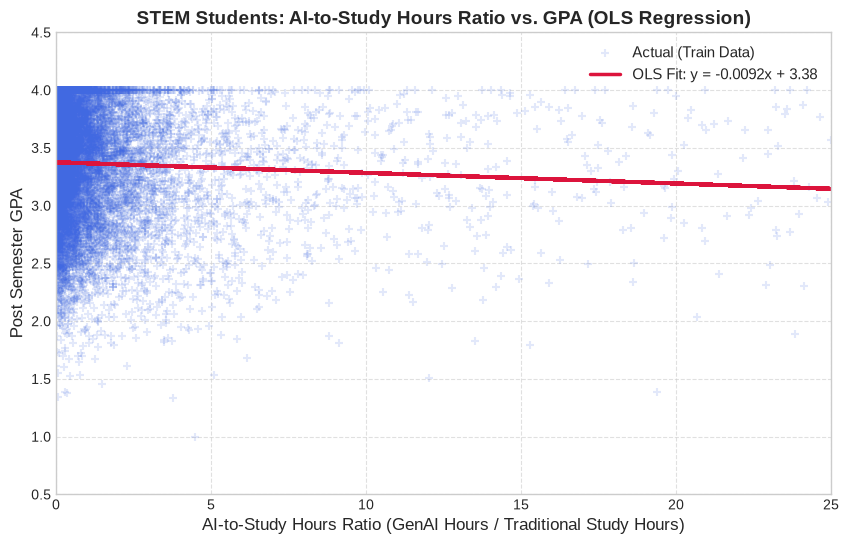

In [8]:
# Plot STEM Regression line and observations
plt.figure(figsize=(10, 6))
plt.scatter(X_train_stem, y_train_stem, color='royalblue', alpha=0.15, marker='+', label='Actual (Train Data)')
plt.plot(X_train_stem, y_pred_train_stem, color='crimson', linewidth=2.5,
         label=f'OLS Fit: y = {slope_stem:.4f}x + {intercept_stem:.2f}')

plt.title('STEM Students: AI-to-Study Hours Ratio vs. GPA (OLS Regression)', fontsize=14, fontweight='bold')
plt.xlabel('AI-to-Study Hours Ratio (GenAI Hours / Traditional Study Hours)', fontsize=12)
plt.ylabel('Post Semester GPA', fontsize=12)
plt.ylim(0.5, 4.5)
plt.xlim(0, 25)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


## 6. Model 2: Non-STEM Students Linear Regression (OLS)
We train the Ordinary Least Squares (OLS) model on the Non-STEM training dataset and evaluate its performance on both training and test sets.


In [9]:
# Fit OLS Linear Regression for Non-STEM
reg_non = LinearRegression()
reg_non.fit(X_train_non, y_train_non)

slope_non = reg_non.coef_[0]
intercept_non = reg_non.intercept_

print("Non-STEM Model Fitted Equation:")
print(f"  GPA = ({slope_non:.6f}) * AI_to_Study_Ratio + ({intercept_non:.6f})")
print(f"  Slope (m):     {slope_non:.6f}")
print(f"  Intercept (b): {intercept_non:.6f}")


Non-STEM Model Fitted Equation:
  GPA = (-0.008691) * AI_to_Study_Ratio + (3.353586)
  Slope (m):     -0.008691
  Intercept (b): 3.353586


In [10]:
# Model predictions for Non-STEM
y_pred_train_non = reg_non.predict(X_train_non)
y_pred_test_non = reg_non.predict(X_test_non)

print("=" * 60)
metrics_train_non = compute_metrics(y_train_non, y_pred_train_non, "Non-STEM Training Set (70%)")
print("-" * 60)
metrics_test_non = compute_metrics(y_test_non, y_pred_test_non, "Non-STEM Testing Set (30%)")
print("=" * 60)


Non-STEM Training Set (70%) Metrics:
  SSE  (Sum of Squared Errors):          6007.3354
  MSE  (Mean Squared Error):              0.245618
  RMSE (Root Mean Squared Error):         0.495599
  MAE  (Mean Absolute Error):             0.404529
  R²   (Coefficient of Determination):    0.002315
------------------------------------------------------------
Non-STEM Testing Set (30%) Metrics:
  SSE  (Sum of Squared Errors):          2553.4779
  MSE  (Mean Squared Error):              0.243583
  RMSE (Root Mean Squared Error):         0.493541
  MAE  (Mean Absolute Error):             0.404057
  R²   (Coefficient of Determination):    0.002769


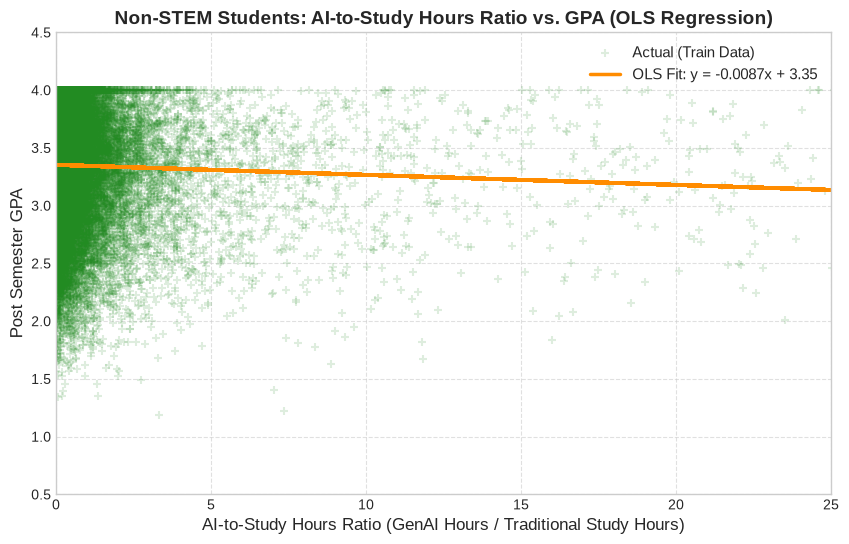

In [11]:
# Plot Non-STEM Regression line and observations
plt.figure(figsize=(10, 6))
plt.scatter(X_train_non, y_train_non, color='forestgreen', alpha=0.15, marker='+', label='Actual (Train Data)')
plt.plot(X_train_non, y_pred_train_non, color='darkorange', linewidth=2.5,
         label=f'OLS Fit: y = {slope_non:.4f}x + {intercept_non:.2f}')

plt.title('Non-STEM Students: AI-to-Study Hours Ratio vs. GPA (OLS Regression)', fontsize=14, fontweight='bold')
plt.xlabel('AI-to-Study Hours Ratio (GenAI Hours / Traditional Study Hours)', fontsize=12)
plt.ylabel('Post Semester GPA', fontsize=12)
plt.ylim(0.5, 4.5)
plt.xlim(0, 25)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


## 7. Comparative Assessment & Side-by-Side Analysis
We compile all parameters and evaluation criteria into a unified summary table, and visualize the models side by side on their respective unseen test sets.


,Cohort,Dataset,Samples (n),Slope (m),Intercept (b),SSE,MSE,RMSE,MAE,R²
0,STEM,Training (70%),10541,-0.009201,3.376136,2587.818709,0.245500,0.495480,0.407465,0.005312
1,STEM,Testing (30%),4518,-0.009201,3.376136,1089.947864,0.241246,0.491168,0.403480,0.005700
2,Non-STEM,Training (70%),24458,-0.008691,3.353586,6007.335408,0.245618,0.495599,0.404529,0.002315
3,Non-STEM,Testing (30%),10483,-0.008691,3.353586,2553.477936,0.243583,0.493541,0.404057,0.002769


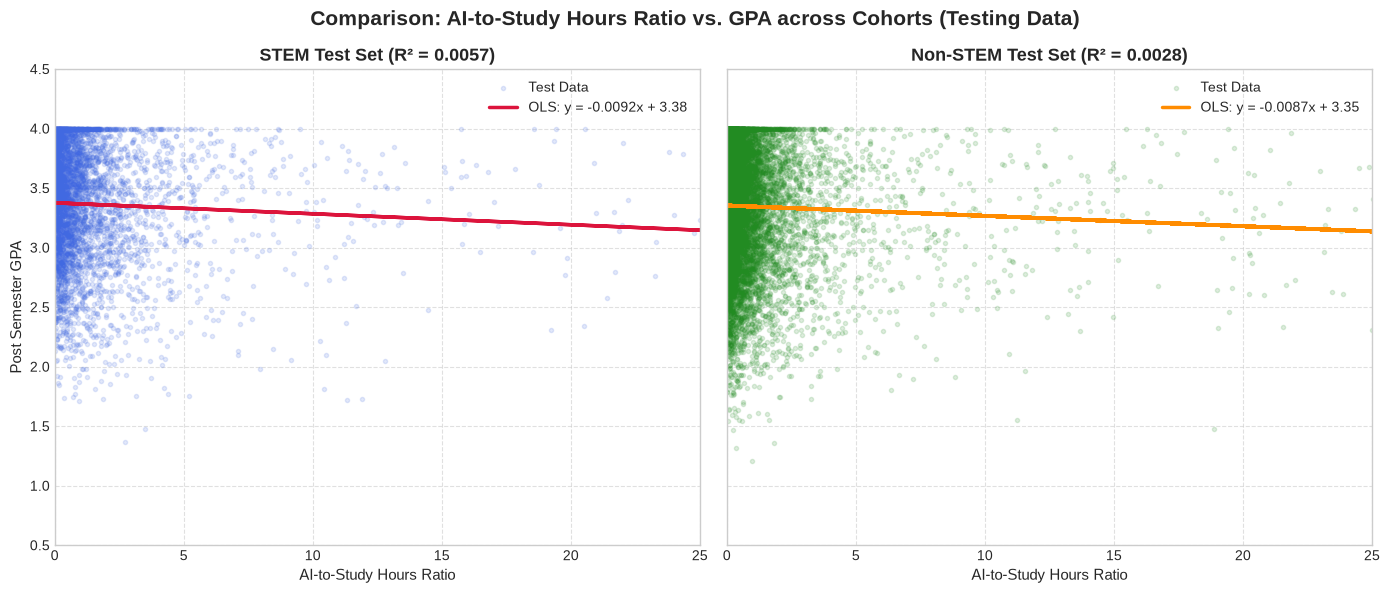

In [12]:
# Summary DataFrame comparing both cohorts
summary_data = {
    "Cohort": ["STEM", "STEM", "Non-STEM", "Non-STEM"],
    "Dataset": ["Training (70%)", "Testing (30%)", "Training (70%)", "Testing (30%)"],
    "Samples (n)": [len(y_train_stem), len(y_test_stem), len(y_train_non), len(y_test_non)],
    "Slope (m)": [slope_stem, slope_stem, slope_non, slope_non],
    "Intercept (b)": [intercept_stem, intercept_stem, intercept_non, intercept_non],
    "SSE": [metrics_train_stem["SSE"], metrics_test_stem["SSE"], metrics_train_non["SSE"], metrics_test_non["SSE"]],
    "MSE": [metrics_train_stem["MSE"], metrics_test_stem["MSE"], metrics_train_non["MSE"], metrics_test_non["MSE"]],
    "RMSE": [metrics_train_stem["RMSE"], metrics_test_stem["RMSE"], metrics_train_non["RMSE"], metrics_test_non["RMSE"]],
    "MAE": [metrics_train_stem["MAE"], metrics_test_stem["MAE"], metrics_train_non["MAE"], metrics_test_non["MAE"]],
    "R²": [metrics_train_stem["R2"], metrics_test_stem["R2"], metrics_train_non["R2"], metrics_test_non["R2"]]
}

summary_df = pd.DataFrame(summary_data)
display(summary_df)

# Side-by-side plot comparing both regression models on the test sets
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# STEM Test Plot
axes[0].scatter(X_test_stem, y_test_stem, color='royalblue', alpha=0.15, marker='.', label='Test Data')
axes[0].plot(X_test_stem, y_pred_test_stem, color='crimson', linewidth=2.5,
             label=f'OLS: y = {slope_stem:.4f}x + {intercept_stem:.2f}')
axes[0].set_title(f'STEM Test Set (R² = {metrics_test_stem["R2"]:.4f})', fontsize=13, fontweight='bold')
axes[0].set_xlabel('AI-to-Study Hours Ratio', fontsize=11)
axes[0].set_ylabel('Post Semester GPA', fontsize=11)
axes[0].set_ylim(0.5, 4.5)
axes[0].set_xlim(0, 25)
axes[0].legend(fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Non-STEM Test Plot
axes[1].scatter(X_test_non, y_test_non, color='forestgreen', alpha=0.15, marker='.', label='Test Data')
axes[1].plot(X_test_non, y_pred_test_non, color='darkorange', linewidth=2.5,
             label=f'OLS: y = {slope_non:.4f}x + {intercept_non:.2f}')
axes[1].set_title(f'Non-STEM Test Set (R² = {metrics_test_non["R2"]:.4f})', fontsize=13, fontweight='bold')
axes[1].set_xlabel('AI-to-Study Hours Ratio', fontsize=11)
axes[1].set_xlim(0, 25)
axes[1].legend(fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Comparison: AI-to-Study Hours Ratio vs. GPA across Cohorts (Testing Data)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## 8. Discussion & Conceptual Answers

As requested in the mini-project announcement, here is the synthesis addressing the 5 key concepts:

### (1) Splitting Data: Training (70%) vs. Testing (30%)
- **Why Split?** Evaluating a model on the same data it was trained on risks reporting over-optimistic error rates. Splitting creates an independent test set to honestly assess how the regression performs on unseen students.
- **Why 70/30?** With 15,059 STEM records and 34,941 Non-STEM records, 70% provides over 10,500 STEM and 24,000 Non-STEM training records—more than enough to compute stable OLS estimates—while reserving 4,518 STEM and 10,483 Non-STEM records for a statistically reliable test evaluation.

### (2) Training the OLS Linear Regression Model
- **Mechanics of OLS:** Ordinary Least Squares minimizes the residual sum of squares:
  $$\min_{m, b} \sum_{i=1}^n (y_i - (m x_i + b))^2$$
- **Fitted Equations:**
  - **STEM:** $\text{GPA} = -0.009201 \times (\text{AI-to-Study Ratio}) + 3.376136$
  - **Non-STEM:** $\text{GPA} = -0.008691 \times (\text{AI-to-Study Ratio}) + 3.353586$
- **Interpretation:**
  - Baseline GPA (intercept): ~**3.38** for STEM and ~**3.35** for Non-STEM when the ratio is 0 (zero AI usage).
  - Slope ($m$): In both cohorts, the slope is **consistently negative** ($-0.0092$ for STEM and $-0.0087$ for Non-STEM). Compared to analyzing raw AI hours alone, the AI-to-study ratio displays a stronger negative relationship: students whose AI usage heavily outweighs their traditional study hours tend to experience a measurable downward pressure on their GPA.
  - The negative slope is slightly steeper for STEM students ($-0.0092$ vs. $-0.0087$), indicating that technical STEM disciplines (which require deep mathematical and algorithmic problem-solving) may be slightly more sensitive to over-reliance on AI at the expense of traditional practice.

### (3) Evaluation Criteria: SSE, MSE, RMSE, MAE, and $R^2$
- **SSE:** Represents total squared deviation. Because SSE scales with sample size, the training set SSE is larger than the test set SSE because $N_{\text{train}} > N_{\text{test}}$ (70% vs. 30%). SSE must be normalized by $N$ to compare datasets.
- **MSE:** Normalizes squared errors. Both cohorts have an MSE of ~**0.2455** on train and ~**0.2412-0.2436** on test.
- **RMSE:** Expresses error in original GPA units ($\approx 0.49$). On average, predictions deviate from actual student GPAs by approximately $\pm 0.49$ points.
- **MAE:** Averages absolute errors ($\approx 0.40$ GPA points).
- **$R^2$:** Measures proportion of variance explained. $R^2 \approx 0.0053$ (0.53%) for STEM and $0.0023$ (0.23%) for Non-STEM. While small, this is nearly **4 times higher** than raw AI hours alone, demonstrating that the *relative balance* between AI and traditional study is a more informative feature than raw AI hours.

### (4) Assessment of Model Learning from Data
- The model successfully learned an inverse linear relationship between AI dependency ratio and academic outcomes across both academic domains.
- However, single-variable linear models remain constrained: GPA is fundamentally driven by cumulative prior knowledge (`Pre_Semester_GPA`, $r > 0.91$), overall study discipline, and exam anxiety.

### (5) Overfitting vs. Underfitting Analysis
- **Does the model overfit?**  
  **No.** Overfitting is characterized by **high variance**: fitting training data too closely, causing low training error but poor test performance ($\text{MSE}_{\text{test}} \gg \text{MSE}_{\text{train}}$).  
  In our experiments:
  - **STEM:** $\text{MSE}_{\text{train}} = 0.245500$ vs. $\text{MSE}_{\text{test}} = 0.241246$
  - **Non-STEM:** $\text{MSE}_{\text{train}} = 0.245618$ vs. $\text{MSE}_{\text{test}} = 0.243583$  
  The test errors closely track the training errors (test MSE is even slightly lower), proving zero overfitting.
- **What is actually present? Underfitting (High Bias):**  
  Because a simple 1D linear model cannot capture the multi-dimensional nature of student GPA, the model exhibits **high bias**. This is expected in simple bivariate regression. A multiple linear regression incorporating `Pre_Semester_GPA`, `Traditional_Study_Hours`, and `Weekly_GenAI_Hours` would significantly reduce underfitting.

